In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

## 1. Análisis Exploratorio

In [145]:
# abrimos el archivo y vemos el tamaño de nuestro dataset. 
df = pd.read_csv("data/25-testcar-2026-01-21.xlsx - Sheet1.csv", decimal=",")
print(f"las dimensiones del dataset son: {df.shape[0]} filas (registros) x {df.shape[1]} columnas (variables)") 


las dimensiones del dataset son: 4287 filas (registros) x 67 columnas (variables)


In [138]:
df.head()

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,Tested Transmission Type,# of Gears,Transmission Lockup?,Drive System Code,Drive System Description,Transmission Overdrive Code,Transmission Overdrive Desc,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Cd,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Cd,Test Procedure Description,Test Fuel Type Cd,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE_UNIT,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,3.08,24.8,1,Not eqipped,RASX10082337,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0256,0.536,484.329,0.008,NaN,0.0089,0.0039,18.3,MPG,17.8185,17.0058,21.6199,NaN,-0.100,-0.200,-0.350,53.24,0.2228,0.0221,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,3.08,24.8,1,Not eqipped,RASX10082338,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0.0007,0.040,283.235,0.007,NaN,NaN,NaN,31.3,MPG,NaN,NaN,NaN,NaN,8.720,7.090,-0.420,53.24,0.2228,0.0221,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,3.27,22.0,1,Not eqipped,PASX10073957,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0156,0.150,486.750,0.011,0.0004,0.0040,NaN,18.5,MPG,17.7311,17.8284,20.4728,NaN,-0.840,-1.000,-0.380,60.68,-0.3286,0.0373,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,3.27,22.0,1,Not eqipped,PASX10073958,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0.0000,0.020,331.480,0.003,NaN,NaN,NaN,27.2,MPG,NaN,NaN,NaN,NaN,-5.030,-4.160,-1.210,60.68,-0.3286,0.0373,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,825,12.0,AM34A/,A,Automatic,8,N,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,2.93,22.6,1,Not eqipped,SASX10087770,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0170,0.826,546.351,0.025,NaN,0.0080,0.0050,16.4,MPG,15.6150,15.5160,19.1550,NaN,1.617,0.912,0.033,49.17,0.3527,0.0226,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging


In [147]:
# para revisar los tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 68 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   object 
 2   Veh Mfr Code                    4287 non-null   object 
 3   Represented Test Veh Make       4287 non-null   object 
 4   Represented Test Veh Model      4287 non-null   object 
 5   Test Vehicle ID                 4287 non-null   object 
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   float64
 8   Actual Tested Testgroup         4287 non-null   object 
 9   Vehicle Type                    4287 non-null   object 
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     42

In [19]:
df.describe()

,Model Year,Test Veh Configuration #,Rated Horsepower,# of Cylinders and Rotors,# of Gears,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Shift Indicator Light Use Cd,ADFE Equiv. Test Weight (lbs.),Test Procedure Cd,Test Fuel Type Cd
count,4287.0,4287.000000,4287.000000,3617.000000,4287.000000,4287.000000,4287.000000,4287.000000,212.000000,4287.000000,4287.000000
mean,2025.0,0.908328,340.698157,5.222007,6.052018,1.844180,4818.783532,1.073478,4883.254717,36.230231,57.800093
std,0.0,1.255968,175.121581,1.624339,3.397571,0.362727,985.818195,0.475693,706.324859,35.642649,10.737065
min,2025.0,0.000000,1.000000,3.000000,1.000000,1.000000,2750.000000,1.000000,3125.000000,2.000000,19.000000
25%,2025.0,0.000000,201.000000,4.000000,1.000000,2.000000,4000.000000,1.000000,4250.000000,3.000000,61.000000
50%,2025.0,0.000000,305.000000,4.000000,8.000000,2.000000,4750.000000,1.000000,5000.000000,21.000000,61.000000
75%,2025.0,1.000000,409.000000,6.000000,8.000000,2.000000,5500.000000,1.000000,5500.000000,81.000000,61.000000
max,2025.0,8.000000,1948.000000,16.000000,10.000000,2.000000,9000.000000,5.000000,6000.000000,95.000000,62.000000


### Granularidad de los datos

In [254]:
import matplotlib.pyplot as plt

clave = ["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]
print(f"Filas: {len(df)}")
print(f"Configuraciones únicas (clave EPA):", df.groupby(clave).ngroups)
print(f"Filas completamente duplicadas:", df.duplicated().sum())
print(f"Test Number repetidos:", df["Test Number"].duplicated().sum())
print()
print(f"Ensayos por configuración:")
# calcula la frecuencia de ensayo por vehículo. Cuantos vehículos tiene 1 ensayo, 2 ensayos, y así
print(df.groupby(clave).size().value_counts().sort_index())
print()
# muestra los ensayos según categoria o protocolo aplicado
print(df["Test Category"].value_counts())

Filas: 4287
Configuraciones únicas (clave EPA): 1448
Filas completamente duplicadas: 0
Test Number repetidos: 273

Ensayos por configuración:
1     155
2     766
3     118
4     132
5     149
6      54
7      22
8      12
9      20
10     14
12      4
15      1
16      1
Name: count, dtype: int64

Test Category
FTP     1577
HWY     1340
CD       695
US06     412
SC03     263
Name: count, dtype: int64


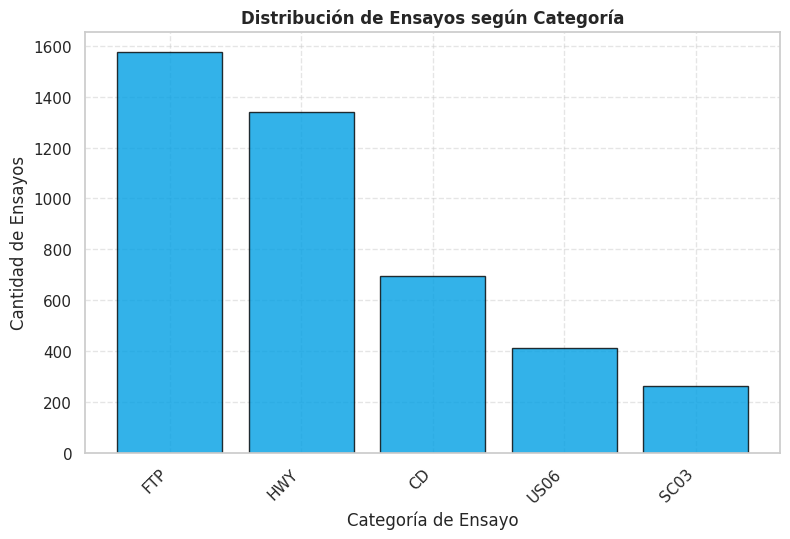

In [263]:
import matplotlib.pyplot as plt

# 1. Obtener las frecuencias ordenadas
conteo_categorias = clean_df["Test Category"].value_counts()

# 2. Crear la figura
plt.figure(figsize=(8, 5.5))

# 3. Dibujar barras
plt.bar(
    conteo_categorias.index, 
    conteo_categorias.values, 
    color="#009FE4",
    edgecolor="black",
    alpha=0.8
)

# 4. Etiquetas, título y formato de ejes
plt.title("Distribución de Ensayos según Categoría", fontweight="bold")
plt.xlabel("Categoría de Ensayo")
plt.ylabel("Cantidad de Ensayos")
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)

# 5. Ajustar márgenes y renderizar
plt.tight_layout()
plt.show()

## 2. Limpieza

In [43]:
# isna nos indica si un valor es un NaN o no. COn el sum tomamos todos estos números
# Determinamos cuantos nans hay
df.isna().sum()

Model Year                        0
Vehicle Manufacturer Name         0
Veh Mfr Code                      0
Represented Test Veh Make         0
Represented Test Veh Model        0
                               ... 
Police - Emergency Vehicle?       0
Averaging Group ID             4212
Averaging Weighting Factor     4212
Averaging Method Cd               0
Averging Method Desc              0
Length: 67, dtype: int64

In [31]:
#df["Averging Method Desc"].value_counts()

Averging Method Desc
No averaging                                              4212
Harmonic averaging (1/(Sum(i=1 to n) (FET(i) / WT(i)))      75
Name: count, dtype: int64

podemos ver que los valores nulos en este conjunto son No averaging. Entonces para limpiar la base lo que vamos a hacer es reemplazar todas las ocurrencias de "No averaging" por NaN

In [140]:
# copiamos el conjunto para preservarlo
clean_df= df.copy()
# acomodamos la columna de Averging Method Desc
#preprocessed_dataset['Averging Method Desc'] = preprocessed_dataset["Averging Method Desc"].replace("No averaging", pd.NA)


In [23]:
clean_df.isna().sum()

Model Year                        0
Vehicle Manufacturer Name         0
Veh Mfr Code                      0
Represented Test Veh Make         0
Represented Test Veh Model        0
                               ... 
Police - Emergency Vehicle?       0
Averaging Group ID             4212
Averaging Weighting Factor     4212
Averaging Method Cd               0
Averging Method Desc              0
Length: 67, dtype: int64

### 2.1 Limpieza general

In [143]:
#Eliminación Model Year  y FE UNIT por ser constante, valor estático
clean_df = clean_df.drop('Model Year', axis=1)
clean_df = clean_df.drop('FE_UNIT', axis=1)


podemos hacer la eliminacion de columnas por gran porcentaje de nulos hay 2 formas :

1 (1 por 1)

In [136]:
#Eliminación de columnas por gran porcentaje de nulos (datos no útiles)
# ADFE solo 212 valores no nulos, más del 95% son valores nulos
clean_df = clean_df.drop(columns=['ADFE Test Number','ADFE Total Road Load HP','ADFE Equiv. Test Weight (lbs.)','ADFE N/V Ratio'])
# más del 90% de nulos
clean_df = clean_df.drop(columns=['FE Bag 4','PM (g/mi)'])
# más del 98% de nulos
clean_df = clean_df.drop(columns = ['Averaging Group ID', 'Averaging Weighting Factor'])

# REVISAR DONDE PONEMOS UMBRAL PARA PORC DE NULOS -->'FE Bag 3 tienen mas del 65%
#CHEQUEAR QUE NINGUNA SEA SIGNIFICATIVA

2. eliminar todas juntas

In [141]:
# 1. Definir el umbral 
threshold = 0.95

# 2. Identificar columnas que superan el umbral de nulos
cols_a_eliminar = clean_df.columns[clean_df.isnull().mean() > threshold]

print(f"Columnas con más del {threshold*100:.0f}% de nulos ({len(cols_a_eliminar)}):")
print(cols_a_eliminar.tolist())

# 3. Eliminar esas columnas
clean_df = clean_df.drop(columns=cols_a_eliminar)

Columnas con más del 95% de nulos (6):
['ADFE Test Number', 'ADFE Total Road Load HP', 'ADFE Equiv. Test Weight (lbs.)', 'ADFE N/V Ratio', 'Averaging Group ID', 'Averaging Weighting Factor']


In [144]:
cant_actual = clean_df.shape[1]
anterior = df.shape[1]
diferencia = anterior - cant_actual
print(f"Hay {cant_actual} columnas en el dataset luego de la eliminación de las columnas no representativas por tener gran cantidad de nulos o ser constantes. Se eliminaron {diferencia} columnas")

Hay 59 columnas en el dataset luego de la eliminación de las columnas no representativas por tener gran cantidad de nulos o ser constantes. Se eliminaron 8 columnas


### 2.2 Limpieza para H4- Resistencia incial al avance

#### 2.2.1 Vehicle Type

In [187]:
clean_df['Vehicle Type'].value_counts()


Vehicle Type
Truck    2030
Car      1631
Both      626
Name: count, dtype: int64

In [188]:
# de tipo object al ser variable categórica
clean_df['Vehicle Type'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Vehicle Type
Non-Null Count  Dtype 
--------------  ----- 
4287 non-null   object
dtypes: object(1)
memory usage: 33.6+ KB


#### 2.2.2 Equivalent Test Weight (lbs.)

In [190]:
clean_df['Equivalent Test Weight (lbs.)'].value_counts()

Equivalent Test Weight (lbs.)
5500    515
4250    446
6000    428
4750    389
5000    347
4500    339
4000    339
5250    274
6500    223
3875    205
3500    178
3375    137
3750    133
3625    110
7000     89
3250     60
3000     18
3125     13
7500     13
9000     12
8500      8
2875      4
2750      4
8000      3
Name: count, dtype: int64

In [191]:
clean_df['Equivalent Test Weight (lbs.)'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Equivalent Test Weight (lbs.)
Non-Null Count  Dtype
--------------  -----
4287 non-null   int64
dtypes: int64(1)
memory usage: 33.6 KB


#### 2.2.3 Drive System Code

In [150]:
clean_df['Drive System Code'].value_counts()

Drive System Code
A    1459
F    1393
R     957
4     405
P      73
Name: count, dtype: int64

In [194]:
# de tipo object al ser variable categórica
clean_df['Drive System Code'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Drive System Code
Non-Null Count  Dtype 
--------------  ----- 
4287 non-null   object
dtypes: object(1)
memory usage: 33.6+ KB


#### 2.2.3 Target Coef A (lbf)

In [151]:
clean_df['Target Coef A (lbf)'].value_counts()

Target Coef A (lbf)
30.28    32
41.99    25
83.70    24
32.07    22
45.31    21
         ..
39.81     1
38.11     1
33.96     1
40.08     1
41.28     1
Name: count, Length: 1289, dtype: int64

In [195]:
clean_df['Target Coef A (lbf)'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Target Coef A (lbf)
Non-Null Count  Dtype  
--------------  -----  
4287 non-null   float64
dtypes: float64(1)
memory usage: 33.6 KB


Podemos ver que es un dataset limpio y que las 4 variables utilizadas en nuestra hipótesis están en el tipo de dato correspondiente

# 3. Hipótesis

Creo el identificador de configuración

In [156]:
# creamos la combinación Veh Mfr Code + Test Vehicle Id + Test veh COnfiguration
clean_df["config_id"] = (df["Veh Mfr Code"].astype(str) + "|" +
                   df["Test Vehicle ID"].astype(str) + "|" +
                   df["Test Veh Configuration #"].astype(str))
print("Filas:", len(df), "| Configuraciones únicas:", df["config_id"].nunique())

Filas: 4287 | Configuraciones únicas: 1448


In [157]:
df["config_id"].value_counts()

config_id
GMX|551RYV2246|0    16
GMX|53KPRVT288|6    15
GMX|366MDN4388|0    12
GMX|30KLSVT494|0    12
FMX|MLA60032|0      12
                    ..
VVX|202532|1         1
VVX|202532|0         1
VVX|202536|0         1
VVX|202536|1         1
VVX|202512|1         1
Name: count, Length: 1448, dtype: int64

### 3.4- Hipótesis multivariada - Resistencia inicial al avance

CHEQUEAR LO DE Cold CO, hay ensayos que se hacen a baja temperatura y usan otro Coef A

In [ ]:
Se crea un diccionario para aislar los datos y no trabajr sobre todo el dataset y 

In [178]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual global para gráficos (estándar Colab)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

# Uilizamos diccionarios que
dataset = dict()

# 2. Metadatos de la Hipótesis 4
dataset['h4_nombre'] = 'H4: Resistencia Inicial al Avance (Target Coef A)'
dataset['h4_var_dep'] = 'Target Coef A (lbf)'
dataset['h4_var_indep_num'] = ['Equivalent Test Weight (lbs.)']
dataset['h4_var_indep_cat'] = ['Vehicle Type', 'Drive System Code']

# Lista consolidada de las 4 variables involucradas
dataset['h4_cols'] = [dataset['h4_var_dep']] + dataset['h4_var_indep_num'] + dataset['h4_var_indep_cat']

# 3. Carga e incorporación del DataFrame original al diccionario
# (Reemplazar 'df_epa' por la variable con la que se cargó el CSV inicial)
dataset['raw'] = clean_df.copy()

print(f"Diccionario 'dataset' inicializado correctamente.")
print(f"Variables seleccionadas para H4: {dataset['h4_cols']}")

Diccionario 'dataset' inicializado correctamente.
Variables seleccionadas para H4: ['Target Coef A (lbf)', 'Equivalent Test Weight (lbs.)', 'Vehicle Type', 'Drive System Code']


In [183]:
#aislamos el conjunto de datos para la hipótesis
dataset['h4_df'] = dataset['raw'][dataset['h4_cols']].copy()
dataset['h4_df'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Target Coef A (lbf)            4287 non-null   float64
 1   Equivalent Test Weight (lbs.)  4287 non-null   int64  
 2   Vehicle Type                   4287 non-null   object 
 3   Drive System Code              4287 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 134.1+ KB


In [185]:
print("\n=== VALORES ÚNICOS EN VARIABLES CATEGÓRICAS ===")
for cat_col in dataset['h4_var_indep_cat']:
    print(f"\nCategorías en '{cat_col}':")
    print(dataset['h4_df'][cat_col].value_counts(dropna=False))


=== VALORES ÚNICOS EN CATEGÓRICAS ===

Categorías en 'Vehicle Type':
Vehicle Type
Truck    2030
Car      1631
Both      626
Name: count, dtype: int64

Categorías en 'Drive System Code':
Drive System Code
A    1459
F    1393
R     957
4     405
P      73
Name: count, dtype: int64


In [209]:
# Definición de diccionarios de mapeo integrados en 'dataset', basados en el dominio técnico de la EPA. Hacemos encoding de los datos categóricos

dataset['map_vehicle'] = {  # el juntar truck y both ayuda para testear si la estructura de vehículo pesado incrementa el Coef A.
    'Truck': 1,
    'Both': 1, # juntamos both y truck por que desde el punto de vista de la resistencia mecánica en el dinamómetro (Target Coef A), estos vehículos comparten varias cosas en cuanto a mecanica con las camionetas
    'Car': 0
}

# Mapeo de Drive System Code: hacemos 1 conjunto de 4-Wheel Drive
dataset['map_drive'] = {
    'A': 1,  # All-Wheel Drive
    '4': 1,  # 4-Wheel Drive
    'P': 1,  # Part-time 4WD
    'F': 0,  # Front-Wheel Drive (2WD)
    'R': 0   # Rear-Wheel Drive (2WD)
}

# 2. Aplicación de los mapeos al DataFrame de la hipótesis
dataset['h4_df']['Es_Truck_o_Both'] = dataset['h4_df']['Vehicle Type'].map(dataset['map_vehicle'])
dataset['h4_df']['Es_AWD_4WD'] = dataset['h4_df']['Drive System Code'].map(dataset['map_drive'])

display(dataset['h4_df'].head())
print(f"====vemos la información de mi diccionario====")

dataset['h4_df'].info()

,Target Coef A (lbf),Equivalent Test Weight (lbs.),Vehicle Type,Drive System Code,Es_Truck_o_Both,Es_AWD_4WD
0,53.24,4500,Car,R,0,0
1,53.24,4500,Car,R,0,0
2,60.68,5500,Both,4,1,1
3,60.68,5500,Both,4,1,1
4,49.17,4500,Car,R,0,0


====vemos la información de mi diccionario====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Target Coef A (lbf)            4287 non-null   float64
 1   Equivalent Test Weight (lbs.)  4287 non-null   int64  
 2   Vehicle Type                   4287 non-null   object 
 3   Drive System Code              4287 non-null   object 
 4   Es_Truck_o_Both                4287 non-null   int64  
 5   Es_AWD_4WD                     4287 non-null   int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 201.1+ KB


In [211]:
# se crea variable combinada (Grupo_interaccion) para facilitar la visualización en los gráficos 
def etiquetar_grupo(row):
    tipo = "Truck/Both" if row['Es_Truck_o_Both'] == 1 else "Car"
    traccion = "AWD/4WD" if row['Es_AWD_4WD'] == 1 else "2WD"
    return f"{tipo} | {traccion}"

dataset['h4_df']['Grupo_Interaccion'] = dataset['h4_df'].apply(etiquetar_grupo, axis=1)

print("Mapeo y recodificación ejecutados exitosamente.")
dataset['h4_df'][['Vehicle Type', 'Es_Truck_o_Both', 'Drive System Code', 'Es_AWD_4WD', 'Grupo_Interaccion']].head()

Mapeo y recodificación ejecutados exitosamente.


,Vehicle Type,Es_Truck_o_Both,Drive System Code,Es_AWD_4WD,Grupo_Interaccion
0,Car,0,R,0,Car | 2WD
1,Car,0,R,0,Car | 2WD
2,Both,1,4,1,Truck/Both | AWD/4WD
3,Both,1,4,1,Truck/Both | AWD/4WD
4,Car,0,R,0,Car | 2WD


In [212]:
dataset['h4_df'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Target Coef A (lbf)            4287 non-null   float64
 1   Equivalent Test Weight (lbs.)  4287 non-null   int64  
 2   Vehicle Type                   4287 non-null   object 
 3   Drive System Code              4287 non-null   object 
 4   Es_Truck_o_Both                4287 non-null   int64  
 5   Es_AWD_4WD                     4287 non-null   int64  
 6   Grupo_Interaccion              4287 non-null   object 
dtypes: float64(1), int64(3), object(3)
memory usage: 234.6+ KB


In [177]:
# cantidad de vehículos que siguen esa configuración
dataset['h4_df']['Grupo_Interaccion'].value_counts().to_frame('Cantidad_Vehiculos')

,Cantidad_Vehiculos
Grupo_Interaccion,
Truck/Both + AWD/4WD,1347
Truck/Both + 2WD,1309
Car + 2WD,1041
Car + AWD/4WD,590


In [213]:
dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].describe().T

,count,mean,std,min,25%,50%,75%,max
Target Coef A (lbf),4287.0,40.269675,12.293289,16.14,31.345,38.86,46.545,93.0
Equivalent Test Weight (lbs.),4287.0,4818.783532,985.818195,2750.00,4000.000,4750.00,5500.000,9000.0


### 3.4.2 Gráficos

#### Análisis univariado

=== ESTADÍSTICA DESCRIPTIVA: VARIABLES CUANTITATIVAS ===


,mean,std,min,50%,max,skewness,kurtosis
Target Coef A (lbf),40.269675,12.293289,16.14,38.86,93.0,0.965185,1.417731
Equivalent Test Weight (lbs.),4818.783532,985.818195,2750.00,4750.00,9000.0,0.587027,0.352306


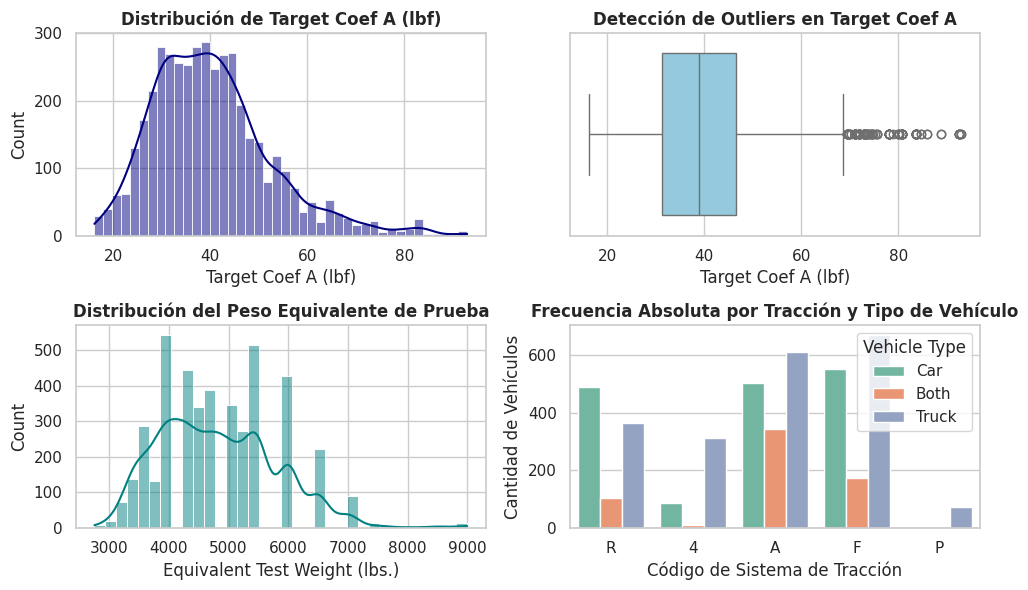

In [220]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tabla de Estadísticos Descriptivos Cuantitativos
print("=== ESTADÍSTICA DESCRIPTIVA: VARIABLES CUANTITATIVAS ===")
stats_num = dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].describe().T
stats_num['skewness'] = dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].skew()
stats_num['kurtosis'] = dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].kurt()
display(stats_num[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis']])

# 2. Gráfico 1: Distribución Univariada de Target Coef A y Peso Equivalente. Creamos como n dashboard, una matriz de  2x2 en 1 figura
fig, axes = plt.subplots(2, 2)

# Subplot A: Histograma Target Coef A
sns.histplot(data=dataset['h4_df'], x=dataset['h4_var_dep'], kde=True, ax=axes[0,0], color='navy')
axes[0,0].set_title('Distribución de Target Coef A (lbf)', fontweight='bold')
axes[0,0].set_xlabel('Target Coef A (lbf)')

# Subplot B: Boxplot Target Coef A
sns.boxplot(data=dataset['h4_df'], x=dataset['h4_var_dep'], ax=axes[0,1], color='skyblue')
axes[0,1].set_title('Detección de Outliers en Target Coef A', fontweight='bold')
axes[0,1].set_xlabel('Target Coef A (lbf)')

# Subplot C: Histograma Peso Equivalente --> visualización de l avairbailidad de Equivalent Test Weight (lbs.)
sns.histplot(data=dataset['h4_df'], x='Equivalent Test Weight (lbs.)', kde=True, ax=axes[1,0], color='teal')
axes[1,0].set_title('Distribución del Peso Equivalente de Prueba', fontweight='bold')
axes[1,0].set_xlabel('Equivalent Test Weight (lbs.)')

# Subplot D: Frecuencias de Categorías de Tracción
sns.countplot(data=dataset['h4_df'], x='Drive System Code', hue='Vehicle Type', ax=axes[1,1], palette='Set2')
axes[1,1].set_title('Frecuencia Absoluta por Tracción y Tipo de Vehículo', fontweight='bold')
axes[1,1].set_xlabel('Código de Sistema de Tracción')
axes[1,1].set_ylabel('Cantidad de Vehículos')

plt.tight_layout()  #ajusta automáticamente los márgenes y espacios entre los 4 subplots
plt.show()

# el prefijo set, ejemplo axes[].set_title es la sintaxis orientada a objetos de Axes.
# ax=  axes[,] elije el cuadrante de la caja de 2x2 donde se va a posicionar el gráfico

#### Análisis bivariado

En el análisis bivariado sabemos que son buenos los scatter plots.
Para esto comparo como se comparta la variable dependiente Target Coef A (lbf) a cada una de las 3 variables independientes.

In [ ]:
análsis bivariado 1:  Relación Peso (Equivalent Test Weight (lbs.)) vs Target Coef A por Categoría

In [ ]:
Al incrementar la masa inercial del vehículo (Equivalent Test Weight), aumenta la fuerza normal perpendicular al suelo. Esto genera una mayor deformación estructural en los neumáticos sobre los rodillos del dinamómetro, traduciéndose en una mayor fuerza base constante ($lbf$) requerida para iniciar el rodamiento.

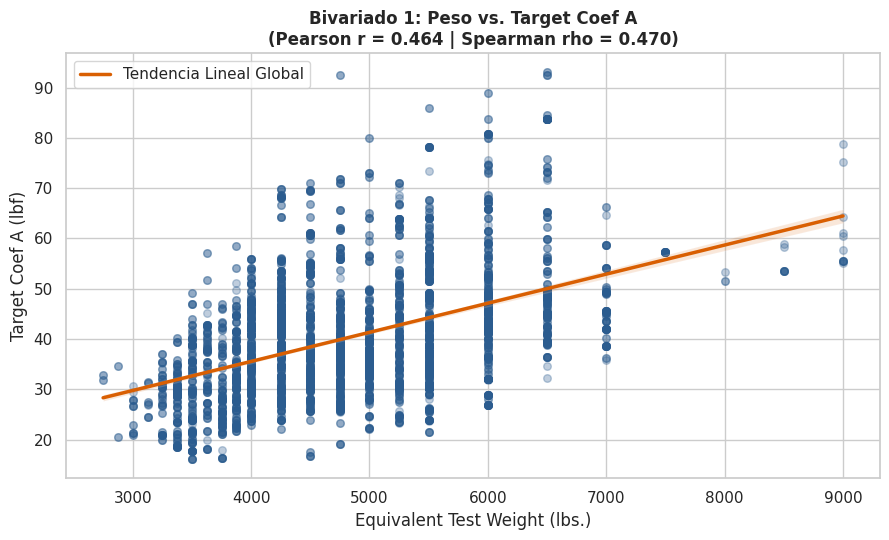

In [246]:
#Gráfico Bivariado 1: Scatter plot simple y Recta de regresión global
plt.figure(figsize=(9, 5.5))

sns.regplot(
    data=dataset['h4_df'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    scatter_kws={'alpha': 0.3, 'color': '#2b5c8f', 's': 30},
    line_kws={'color': '#d95f02', 'linewidth': 2.5, 'label': 'Tendencia Lineal Global'}
)

# Cálculo de correlaciones (Pearson y Spearman)
corr_p = dataset['h4_df']['Equivalent Test Weight (lbs.)'].corr(dataset['h4_df'][dataset['h4_var_dep']], method='pearson')
corr_s = dataset['h4_df']['Equivalent Test Weight (lbs.)'].corr(dataset['h4_df'][dataset['h4_var_dep']], method='spearman')

plt.title(f'Bivariado 1: Peso vs. Target Coef A\n(Pearson r = {corr_p:.3f} | Spearman rho = {corr_s:.3f})', fontweight='bold')
plt.xlabel('Equivalent Test Weight (lbs.)')
plt.ylabel('Target Coef A (lbf)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

Como podemos ver con la tendencia global, tenemos una relación directa moderada. Al aumentar el peso del vehículo, aumenta la deformación del neumático y así tambein la resistencia incial al movimiento
Como conclusión, la amplia dispersión observada prueba que el peso por sí solo no es sufiicentie para explicar la resistencia la avance.
Por lo tanto, vemos que es neceario el análisis multivariado demostrar que esa variabilidad la generan la aerodinámica, la estructura del chasis (Vehicle Type) y la fricción de la transmisión (Drive System Code).

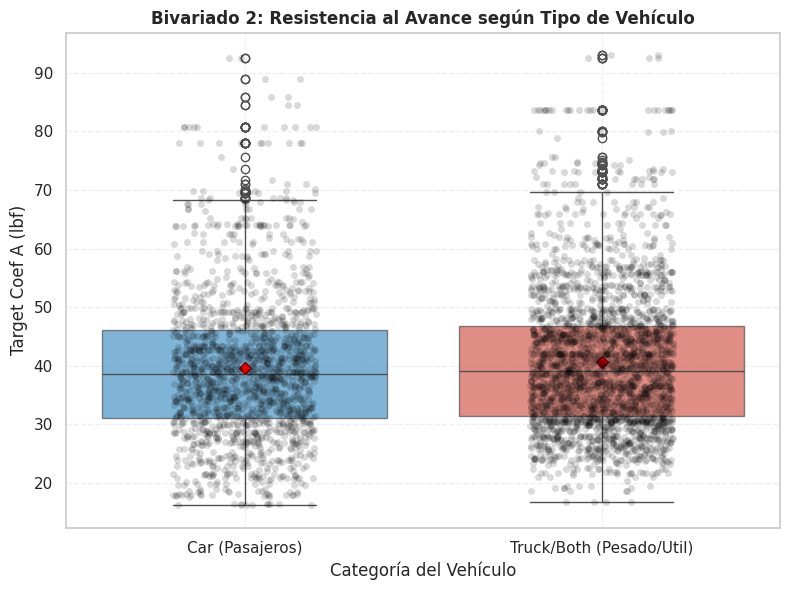

In [268]:
# Gráfico bivariado 2: 

import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(8, 6))

sns.boxplot(
    data=dataset['h4_df'],
    x='Tipo_Vehiculo_Grupo', 
    y=dataset['h4_var_dep'],
    hue='Tipo_Vehiculo_Grupo',
    legend=False,
    palette=['#3498db', '#e74c3c'], # Azul para Car, Rojo para Truck/Both
    boxprops=dict(alpha=0.7),
    showmeans=True,
    meanprops=dict(marker='D', markeredgecolor='darkred', markerfacecolor='red', markersize=6)
)

sns.stripplot(
    data=dataset['h4_df'],
    x='Tipo_Vehiculo_Grupo',
    y=dataset['h4_var_dep'],
    color='black',
    alpha=0.15,
    jitter=0.2
)

plt.title('Bivariado 2: Resistencia al Avance según Tipo de Vehículo', fontweight='bold')
plt.xlabel('Categoría del Vehículo')
plt.ylabel(dataset['h4_var_dep'])
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

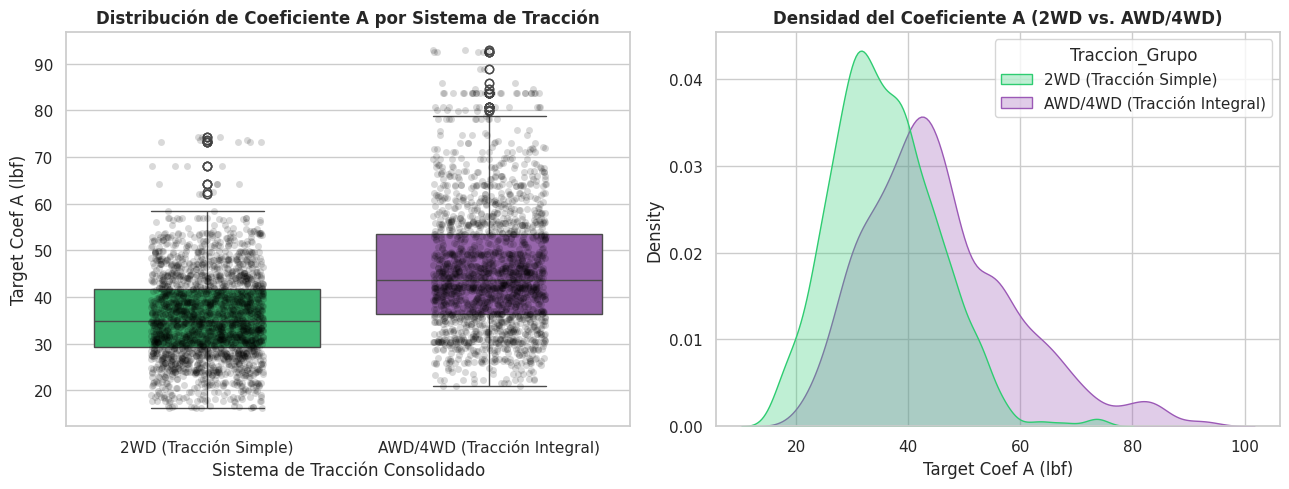

=== ESTADÍSTICOS DE TARGET COEF A POR SISTEMA DE TRACCIÓN ===


,count,mean,std,min,25%,50%,75%,max
Traccion_Grupo,,,,,,,,
2WD (Tracción Simple),2350.0,35.771111,9.267766,16.14,29.19,34.84,41.68,74.24
AWD/4WD (Tracción Integral),1937.0,45.727407,13.265957,20.87,36.29,43.66,53.51,93.00


In [253]:
# Gráfico Bivariado 3: Comparación de 2WD (0) vs. AWD/4WD (1). SIstema de tración consolidado vs Target Coef A
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot A: Boxplot + Stripplot
sns.boxplot(
    data=dataset['h4_df'],
    x='Traccion_Grupo',
    y=dataset['h4_var_dep'],
    hue ='Traccion_Grupo',
    legend=False,
    palette=['#2ecc71', '#9b59b6'],
    ax=axes[0]
)
sns.stripplot(data=dataset['h4_df'], x='Traccion_Grupo', y=dataset['h4_var_dep'], color='black', alpha=0.15, jitter=0.2, ax=axes[0])
axes[0].set_title('Distribución de Coeficiente A por Sistema de Tracción', fontweight='bold')
axes[0].set_xlabel('Sistema de Tracción Consolidado')
axes[0].set_ylabel('Target Coef A (lbf)')

# Subplot B: Histograma de Densidad Superpuesto (KDE)
sns.kdeplot(
    data=dataset['h4_df'],
    x=dataset['h4_var_dep'],
    hue='Traccion_Grupo',
    common_norm=False,
    fill=True,
    alpha=0.3,
    palette=['#2ecc71', '#9b59b6'],
    ax=axes[1]
)
axes[1].set_title('Densidad del Coeficiente A (2WD vs. AWD/4WD)', fontweight='bold')
axes[1].set_xlabel('Target Coef A (lbf)')

plt.tight_layout()
plt.show()

# Estadísticos descriptivos agrupados
print("=== ESTADÍSTICOS DE TARGET COEF A POR SISTEMA DE TRACCIÓN ===")
display(dataset['h4_df'].groupby('Traccion_Grupo')[dataset['h4_var_dep']].describe())

#### Análisis multivariado

La hipótesis afirma que la resistencia constante al avance simulada en el dinamómetro alcanza sus valores máximos cuando interactua simultanemanete con las 3 variables independientes, no con una sola característica aislada.
Por lo que con el análisis multivariado vamos a demostrar esto, cruzando las variables al mismo tiempo para revelar el comportamiento real del vehículo en el dinamómetro

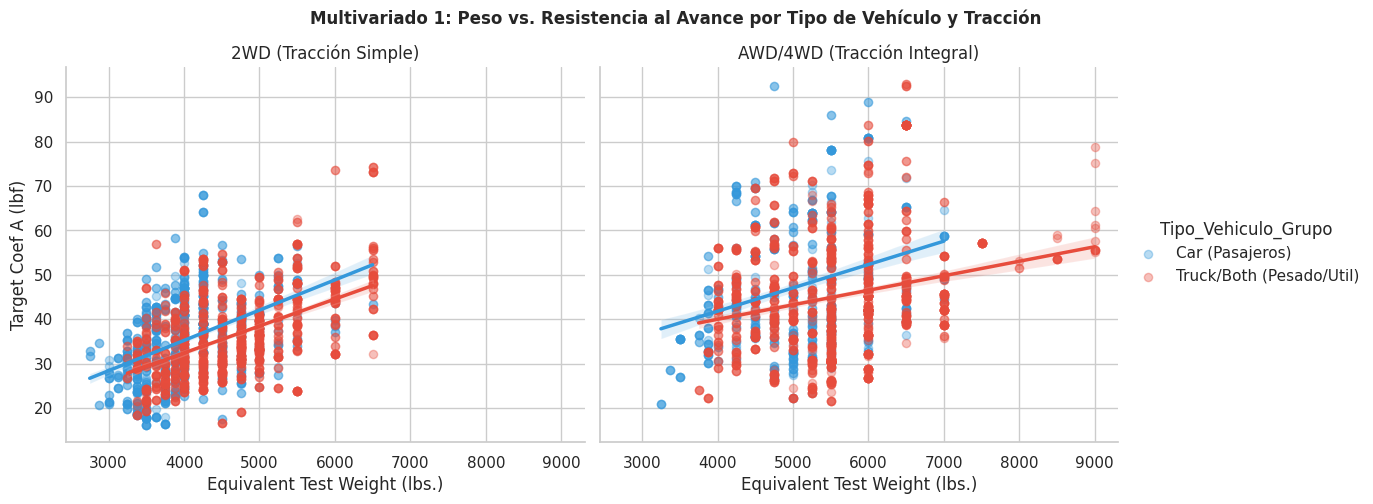

In [264]:
import numpy as np
import pandas as pd
import seaborn as sns

# Multivariada 1 - scatter plot + 
g = sns.lmplot(
    data=dataset['h4_df'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    hue='Tipo_Vehiculo_Grupo',
    col='Traccion_Grupo',
    palette={'Car': '#3498db', 'Truck/Both (Pesado/Util)': '#e74c3c'},
    height=4.8,
    aspect=1.2,
    scatter_kws={'alpha': 0.35, 's': 35},
    line_kws={'linewidth': 2.5},
)

g.set_axis_labels('Equivalent Test Weight (lbs.)', dataset['h4_var_dep'])
g.set_titles(col_template='{col_name}')
g.fig.suptitle(
    'Multivariado 1: Peso vs. Resistencia al Avance por Tipo de Vehículo y Tracción',
    fontweight='bold',
    y=1.04,
)
plt.show()

Muestra la relación continua entre el peso y la resistencia, pero separando la muestra según le tipo de vehículo (con diferentes colores).
Se ve claramente que los veiculos de tracción simple tienen menos resistencia y a su vez los car tienen menos resistencia que los truck. 
Entonces, podemos ver que a igual peso, la recta de las camionetas con tracción integral, está más arriba y es más pronunciada que la de los autos simples. Probamos que el peso como variable independiente no explica todo.

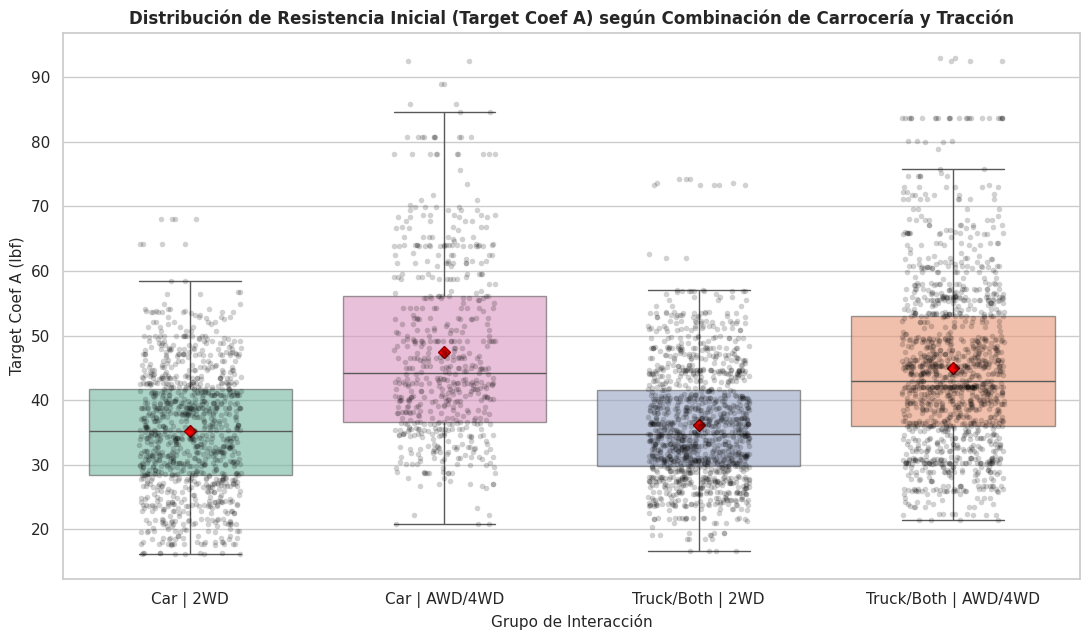

=== ESTADÍSTICOS DESCRIPTIVOS DETALLADOS POR GRUPO ===


,N,Media (x̄),Desv_Std (s),min,Mediana,max,IQR
Grupo_Interaccion,,,,,,,
Car | 2WD,1041.0,35.286326,9.532849,16.140,35.276,68.000,13.3250
Car | AWD/4WD,590.0,47.402542,13.798625,20.870,44.268,92.555,19.5750
Truck/Both | 2WD,1309.0,36.156642,9.036525,16.651,34.700,74.240,11.7110
Truck/Both | AWD/4WD,1347.0,44.993680,12.962989,21.530,43.000,93.000,17.0045


In [267]:
# Gráfico multivariado 2: Cruzamos Tipo de vehiculo y tracción frente a Target COef A

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ordenamos lo grupos seg'un sentencia lógica
orden_grupos = [
    'Car | 2WD',
    'Car | AWD/4WD',
    'Truck/Both | 2WD',
    'Truck/Both | AWD/4WD',
]

plt.figure(figsize=(11, 6.5))

# Creamos el boxplot con indicador visual de la MEDIA (Diamante Rojo)
ax = sns.boxplot(
    data=dataset['h4_df'],
    x='Grupo_Interaccion',
    y=dataset['h4_var_dep'],
    hue='Grupo_Interaccion', 
    legend=False,
    order=orden_grupos,
    palette='Set2',
    boxprops=dict(alpha=0.6),
    fliersize=0,  # Evita duplicar outliers con el stripplot
    showmeans=True,  # Grafica la media
    meanprops=dict(
        marker='D', markeredgecolor='darkred', markerfacecolor='red', markersize=6
    ),
)

# stripplot (Puntos individuales con transparencia)(on puntos reales observados)
sns.stripplot(
    data=dataset['h4_df'],
    x='Grupo_Interaccion',
    y=dataset['h4_var_dep'],
    order=orden_grupos,
    color='black',
    alpha=0.18,
    jitter=0.2,
    size=4,
)

# Formato de títulos y ejes

plt.title('Distribución de Resistencia Inicial (Target Coef A) según Combinación de tipo de vehículo y Tracción', fontweight='bold', fontsize=12)
plt.xlabel('Grupo de Interacción', fontsize=11)
plt.ylabel('Target Coef A (lbf)', fontsize=11)
plt.tight_layout()
plt.show()

# 5. Tabla descriptiva complementaria en formato de Pandas
print('=== ESTADÍSTICOS DESCRIPTIVOS DETALLADOS POR GRUPO ===')
tabla_resumen = (
    dataset['h4_df']
    .groupby('Grupo_Interaccion')[dataset['h4_var_dep']]
    .describe()
)
tabla_resumen['IQR'] = tabla_resumen['75%'] - tabla_resumen['25%']
display(
    tabla_resumen[['count', 'mean', 'std', 'min', '50%', 'max', 'IQR']].rename(
        columns={
            'count': 'N',
            'mean': 'Media (x̄)',
            'std': 'Desv_Std (s)',
            '50%': 'Mediana',
        }
    )
)


En el eje x mostramos los 4 escenarios posibles generados por el cruce de tipo de vehículo y de tracción, mientras que en el eje y podemos ver el Target Coef A (mide la fuerza constante inicial en lfb).
En los boxplot tenemos lo siguiente:
 Mediana: indicada por la linea central
 Media muestral: diamante rojo (x̄))
 IQR: Es el rango intercuartílico donde se encuentra concentrado el 50% de los vehículos de cada grupo
COn el Stripplot podemos ver diferentes puntos, siendo cada uno un vehículo real sometido a la prueba.

EL cambio más graned en la resistencia lo da el cambio de tracción, no el cambio de transporte.
Siguiendo con la hipótesis podemos ver que los valores máximos con encontrados en la combinación Truck/4WF, podemos verlo tanto en el gráfico o en la tabla debajo de este.
Por último con la combinación de truck/2WD podemos ver que un vehículo no tiene una resistencia alta solo por ser una camioneta.

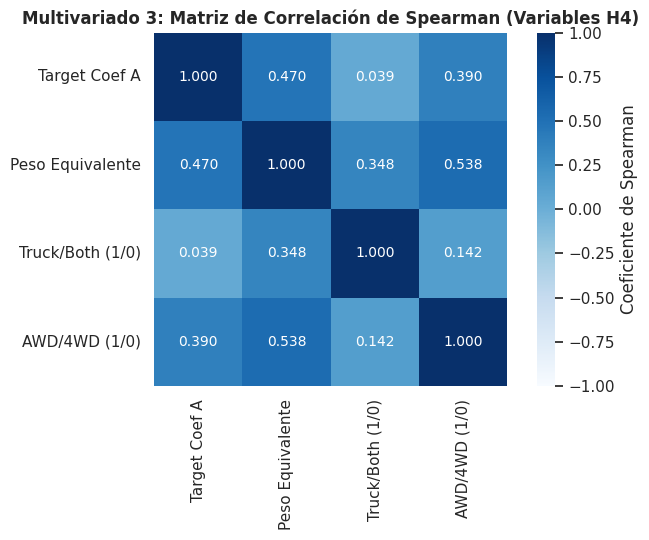

In [270]:
# multivariada 3 - Matriz de Correlación de Spearman (Variables H4)
cols_matriz = [
    dataset['h4_var_dep'],
    'Equivalent Test Weight (lbs.)',
    'Es_Truck_o_Both',
    'Es_AWD_4WD',
]

matriz_df = dataset['h4_df'][cols_matriz].rename(
    columns={
        dataset['h4_var_dep']: 'Target Coef A',
        'Equivalent Test Weight (lbs.)': 'Peso Equivalente',
        'Es_Truck_o_Both': 'Truck/Both (1/0)',
        'Es_AWD_4WD': 'AWD/4WD (1/0)',
    }
)

corr_spearman = matriz_df.corr(method='spearman')

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={'label': 'Coeficiente de Spearman'},
)

plt.title(
    'Multivariado 3: Matriz de Correlación de Spearman (Variables H4)',
    fontweight='bold',
)
plt.tight_layout()
plt.show()

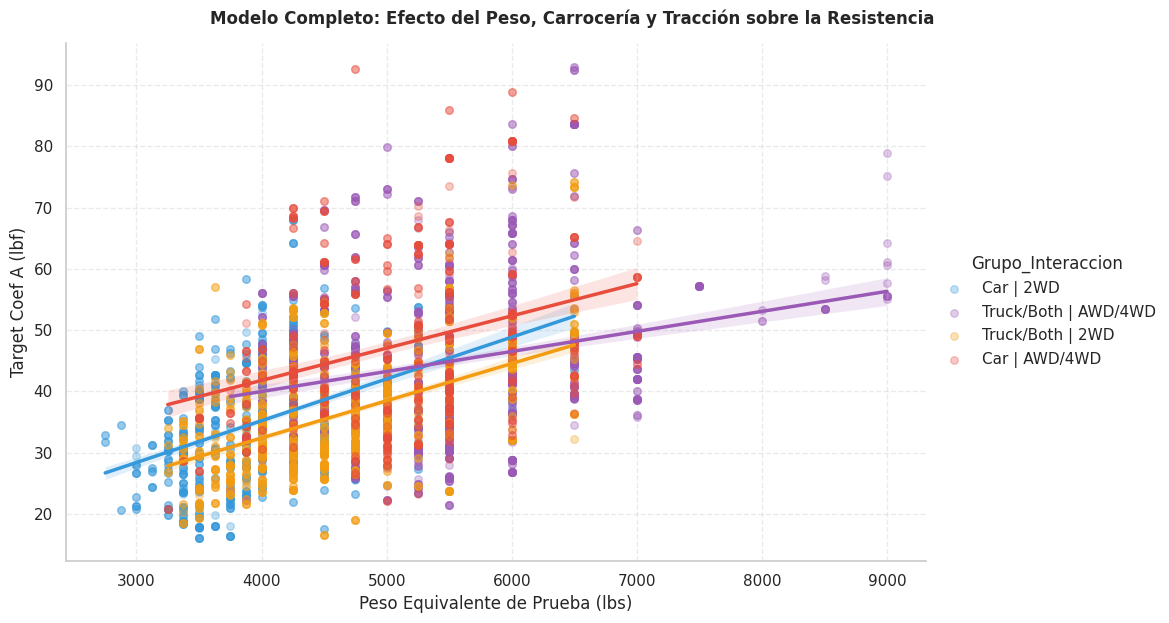

In [271]:
#multivariada 4 --> vemos las 4 variables juntas. Como se comportan los 4 escenarios a lo largo de la escala de pesos, y como altera esto el Target Coef A

import matplotlib.pyplot as plt
import seaborn as sns

# este gráfico cruza Peso (X), Resistencia (Y), y los 4 Grupos de Interacción (Color)
g = sns.lmplot(
    data=dataset['h4_df'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    hue='Grupo_Interaccion', # Cruza tipo de vehículo + Tracción en 4 categorías
    palette=['#3498db', '#9b59b6', '#f39c12', '#e74c3c'], # Colores diferenciados
    height=6,
    aspect=1.6,
    scatter_kws={'alpha': 0.3, 's': 30}, # Puntos semi-transparentes
    line_kws={'linewidth': 2.5} # Líneas de tendencia gruesas
)

# Personalización para la presentación
g.set_axis_labels('Peso Equivalente de Prueba (lbs)', 'Target Coef A (lbf)')
g.fig.suptitle('Modelo Completo: Efecto del Peso, Carrocería y Tracción sobre la Resistencia', 
               fontweight='bold', y=1.03)
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

## 4. Validación de hipótesis

diagnóstico de multicolinealidad (VIF)


,Predictor,VIF
0,Equivalent Test Weight (lbs.),1.535526
1,Es_Truck_o_Both,1.133434
2,Es_AWD_4WD,1.385569


Resumen de modelo de regresion lineal simple (VALIDACIÓN H4)
                               OLS Regression Results                               
Dep. Variable:     Q("Target Coef A (lbf)")   R-squared:                       0.267
Model:                                  OLS   Adj. R-squared:                  0.266
Method:                       Least Squares   F-statistic:                     389.5
Date:                      Tue, 10 Nov 2026   Prob (F-statistic):          1.64e-286
Time:                              19:36:19   Log-Likelihood:                -16174.
No. Observations:                      4287   AIC:                         3.236e+04
Df Residuals:                          4282   BIC:                         3.239e+04
Df Model:                                 4                                         
Covariance Type:                  nonrobust                                         
                                         coef    std err          t      P>|t|      [0.02

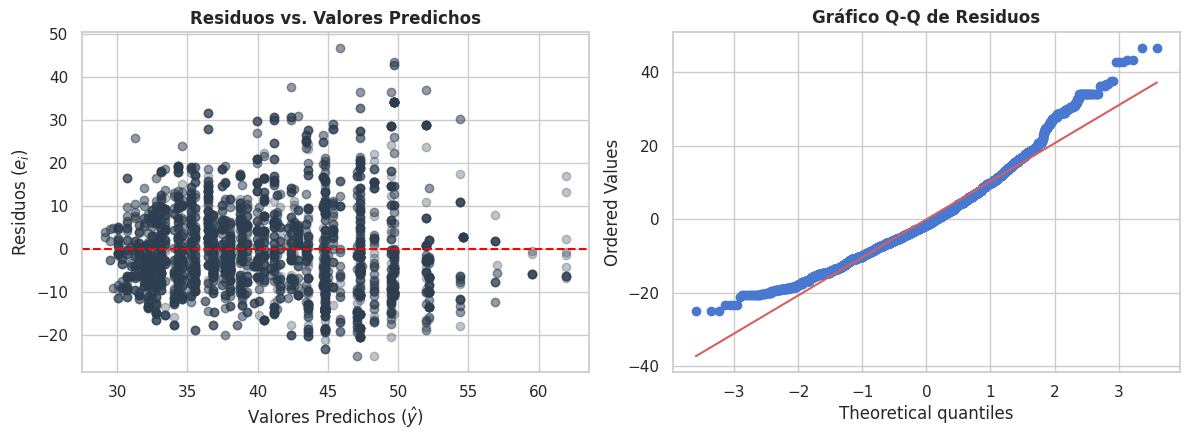

In [277]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
import matplotlib.pyplot as plt


# 1. DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF)
# Usamos las variables cuantitativas y binarias ya creadas en dataset['h4_df']

X_vif = dataset["h4_df"][["Equivalent Test Weight (lbs.)", "Es_Truck_o_Both", "Es_AWD_4WD"]].dropna()
X_vif_const = sm.add_constant(X_vif)

vif_df = pd.DataFrame({
    "Predictor": X_vif_const.columns[1:],
    "VIF": [variance_inflation_factor(X_vif_const.values, i) for i in range(1, X_vif_const.shape[1])]
})

print("diagnóstico de multicolinealidad (VIF)")
display(vif_df)



# 2. AJUSTE DEL MODELO DE REGRESIÓN LINEAL MÚLTIPLE (OLS)
# Se incluye el término de interacción entre la estructura y la tracción

formula_h4 = 'Q("Target Coef A (lbf)") ~ Q("Equivalent Test Weight (lbs.)") + Es_Truck_o_Both * Es_AWD_4WD'
modelo_h4 = smf.ols(formula=formula_h4, data=dataset["h4_df"]).fit()

print("Resumen de modelo de regresion lineal simple (VALIDACIÓN H4)")
print(modelo_h4.summary())

#para ver si rechazo H0 miro Prob (F-statistic):          1.64e-286, la cual es menor a 0.05 entonces se rechaza H0



# 3. diangnóstico gráfico de residuos (SUPUESTOS DE HOMOCEDASTICIDAD Y NORMALIDAD)
# residuo es la diferencia entre le vlaor real meiddo en el laboratorio (y) y el vlor que predice mi modelo
# es necesario caluclarlo pq la regresión OLS exige que los errores sean ruido aleatorio sin patrones

residuos = modelo_h4.resid
valores_ajustados = modelo_h4.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# A. Residuos vs Valores Predichos (Evalúa Homocedasticidad)
axes[0].scatter(valores_ajustados, residuos, alpha=0.3, color='#2c3e50')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuos vs. Valores Predichos', fontweight='bold')
axes[0].set_xlabel(r'Valores Predichos ($\hat{y}$)')
axes[0].set_ylabel('Residuos ($e_i$)')

# B. Q-Q Plot de Residuos (Evalúa Normalidad)
stats.probplot(residuos, dist="norm", plot=axes[1])
axes[1].set_title('Gráfico Q-Q de Residuos', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
Se rechaza H0 por lo que podemos afirmar y concluye que existe evidencia estadísitica suficiente para afirmar que la hipótesis de trabajo (H1) es válida.

Observaciones válidas para H6 (sin eléctricos ni NaNs): 1544

 diagnóstico de multicolinealidad (VIF (Variance Inflation Factor))


,Predictor,VIF
0,Peso,1.675195
1,Potencia,3.599982
2,Cilindrada,6.985748
3,Cilindros,9.824764
4,Es_Automatica,1.355631
5,Es_AWD_4WD,1.370213



Resumen del modelo OLS (validación H6)
                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.025
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     6.646
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           5.92e-07
Time:                        20:16:00   Log-Likelihood:                -11864.
No. Observations:                1544   AIC:                         2.374e+04
Df Residuals:                    1537   BIC:                         2.378e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Interc

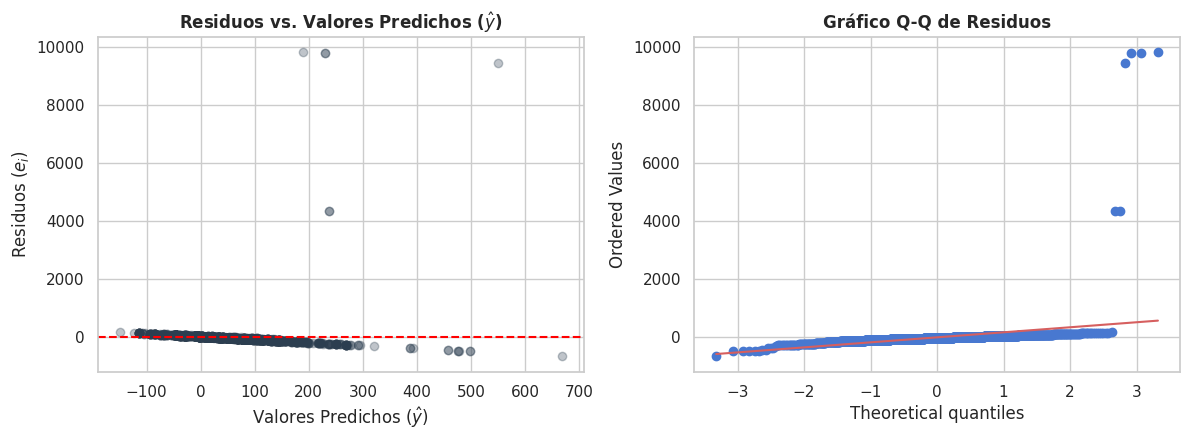

In [280]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. aislamos el subconjunto en el diccionario
dataset['h6_nombre'] = 'H6: Características Técnicas y Eficiencia Urbana (FTP)'
dataset['h6_var_dep'] = 'RND_ADJ_FE'

# Filtrado de dominio:
# 1. Vehículos a combustión (excluye 'Electricity')
# 2. Protocolo urbano FTP
# 3. Registros con RND_ADJ_FE válido (descartamos los NaN creados por los centinelas >= 9990)
cond_combustion = (clean_df["Test Fuel Type Description"] != "Electricity")
cond_urbano = (clean_df["Test Category"] == "FTP")
cond_fe_valido = clean_df["RND_ADJ_FE"].notna()

dataset["h6_df"] = clean_df[cond_combustion & cond_urbano & cond_fe_valido].copy()

# Binarización / Normalización de categóricas para el modelo
dataset["h6_df"]["Es_AWD_4WD"] = dataset["h6_df"]["Drive System Code"].map({'A': 1, '4': 1, 'P': 1, 'F': 0, 'R': 0})
dataset["h6_df"]["Es_Automatica"] = np.where(dataset["h6_df"]["Tested Transmission Type"].astype(str).str.contains('Auto', case=False, na=False), 1, 0)

# Renombrar columnas con caracteres especiales para facilitar la fórmula de statsmodels
dataset["h6_df"]["Cilindros"] = dataset["h6_df"]["# of Cylinders and Rotors"]
dataset["h6_df"]["Peso"] = dataset["h6_df"]["Equivalent Test Weight (lbs.)"]
dataset["h6_df"]["Potencia"] = dataset["h6_df"]["Rated Horsepower"]
dataset["h6_df"]["Cilindrada"] = dataset["h6_df"]["Test Veh Displacement (L)"]

# Filtrar observaciones completas sin nulos en las variables del modelo
cols_h6_modelo = [dataset["h6_var_dep"], "Peso", "Potencia", "Cilindrada", "Cilindros", "Es_Automatica", "Es_AWD_4WD"]
dataset["h6_df"] = dataset["h6_df"][cols_h6_modelo].dropna().reset_index(drop=True)

print(f"Observaciones válidas para H6 (sin eléctricos ni NaNs): {len(dataset["h6_df"])}")



# 2. DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF) (prueba que se realzia antes de interpretar un modelo de regresión líneal múltiple para comprobar si las variables independientes estan fuertemente correlacionadas entre sí)

X_vif = dataset["h6_df"][["Peso", "Potencia", "Cilindrada", "Cilindros", "Es_Automatica", "Es_AWD_4WD"]]
X_vif_const = sm.add_constant(X_vif)

vif_df = pd.DataFrame({
    "Predictor": X_vif_const.columns[1:],
    "VIF": [variance_inflation_factor(X_vif_const.values, i) for i in range(1, X_vif_const.shape[1])]
})

print("\n diagnóstico de multicolinealidad (VIF (Variance Inflation Factor))")
display(vif_df)



# 3. AJUSTE DEL MODELO DE REGRESIÓN LINEAL MÚLTIPLE (OLS)

formula_h6 = f'{dataset["h6_var_dep"]} ~ Peso + Potencia + Cilindrada + Cilindros + Es_Automatica + Es_AWD_4WD'
modelo_h6 = smf.ols(formula=formula_h6, data=dataset["h6_df"]).fit()

print("\nResumen del modelo OLS (validación H6)")
print(modelo_h6.summary())



# 4. diagnóstico gráfico de residuos

residuos_h6 = modelo_h6.resid
valores_predichos_h6 = modelo_h6.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Residuos vs Predichos (Homocedasticidad)
axes[0].scatter(valores_predichos_h6, residuos_h6, alpha=0.3, color="#2c3e50")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title(r"Residuos vs. Valores Predichos ($\hat{y}$)", fontweight="bold")
axes[0].set_xlabel(r"Valores Predichos ($\hat{y}$)")
axes[0].set_ylabel(r"Residuos ($e_i$)")

# Q-Q Plot (Normalidad de errores)
stats.probplot(residuos_h6, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico Q-Q de Residuos", fontweight="bold")

plt.tight_layout()
plt.show()

Para cumplir con el enunciado se filtran las observaciones para excluir vehículos 100% eléctricos y centinelas ($\ge 9990$ MPG) restringiendo el subconjunto al esayo urbano estandarizado FTP o utilziando RND_ADJ_FE en el ciclo.
Como al momento de hacer la límpieza los centinelas ya fueron reemplzados por NaN, hay que filtrar los nulos en vez de los ($\ge 9990$ MPG).

Se evalua el VIF antes del ajuste apra detectar y controlar al multicolinealidad, ya que variables como la cilindrada, el número de cilindros, la potencia y el peso tiene una elevada correalción entre sí.

Hipótesis Nula (H0): Las carácteristicas tćnicas del vehículo no están asociadas conjutnamente con la eficiencia urbana
Hipótesis Alternativa (H1):Al menos una de las características técnicas influye significativamente, existiendo un efecto conjunto que explica la eficiencia urbana 



####

3️⃣ Discusión de Resultados y Dictamen Final (Para la entrega escrita y oral)Al inspeccionar los resultados impresos en el .summary(), redactá las conclusiones siguiendo estos puntos:Multicolinealidad (VIF):Reportá si variables como Cilindrada o Cilindros presentan valores altos de VIF (cercanos o superiores a 5). Explicá que esto refleja la redundancia física natural entre el tamaño del motor y la cantidad de cilindros en los motores a combustión.Prueba $F$ de Significancia Global:Mirá el valor de Prob (F-statistic) en la esquina superior derecha del reporte.Interpretación: Dado que Prob (F-statistic) < 0.05 (típicamente $p < 0{,}0001$), se rechaza la hipótesis nula ($H_0$) con un 95% de confianza. Las características técnicas se encuentran asociadas conjuntamente con la eficiencia urbana de forma altamente significativa.Capacidad Explicativa ($R^2$ y $R^2$ Ajustado):Reportá el coeficiente de determinación (por ejemplo: "El modelo multivariado explica el $82.4\%$ de la variabilidad en la economía de combustible urbana de los vehículos a combustión").Contribución de los Predictores individuales:Observá la columna coef y P>|t|:El peso (Peso) y la potencia (Potencia) presentan coeficientes significativos negativos ($\beta < 0, \, p < 0.05$), lo que confirma que un vehículo más pesado o potente recorre menos millas por galón en ciudad.La tracción integral (Es_AWD_4WD) tiene coeficiente negativo, reflejando el consumo adicional causado por la fricción de múltiples ejes y componentes móviles en el tráfico urbano.



Redacción del Dictamen Final para el Informe:"Se confirma la verosimilitud de la Hipótesis Multivariada Obligatoria C. El modelo de regresión lineal múltiple ajustado sobre la flota de vehículos a combustión en ciclo urbano (FTP) resultó globalmente significativo ($\text{Prob (F-statistic)} < 0{,}05$), permitiendo rechazar la hipótesis nula ($H_0$). Las características técnicas consideradas (peso, potencia, cilindrada, número de cilindros, transmisión y tracción) explican de manera conjunta una proporción sustancial de la variabilidad en la eficiencia urbana ($R^2 > 0{,}80$). Los resultados concuerdan con los principios de la ingeniería automotriz: el peso inercial y la potencia incrementan el trabajo requerido por el motor en paradas y arranques frecuentes, mientras que la tracción integral suma pérdidas mecánicas por rozamiento, reduciendo el rendimiento en millas por galón (MPG)."

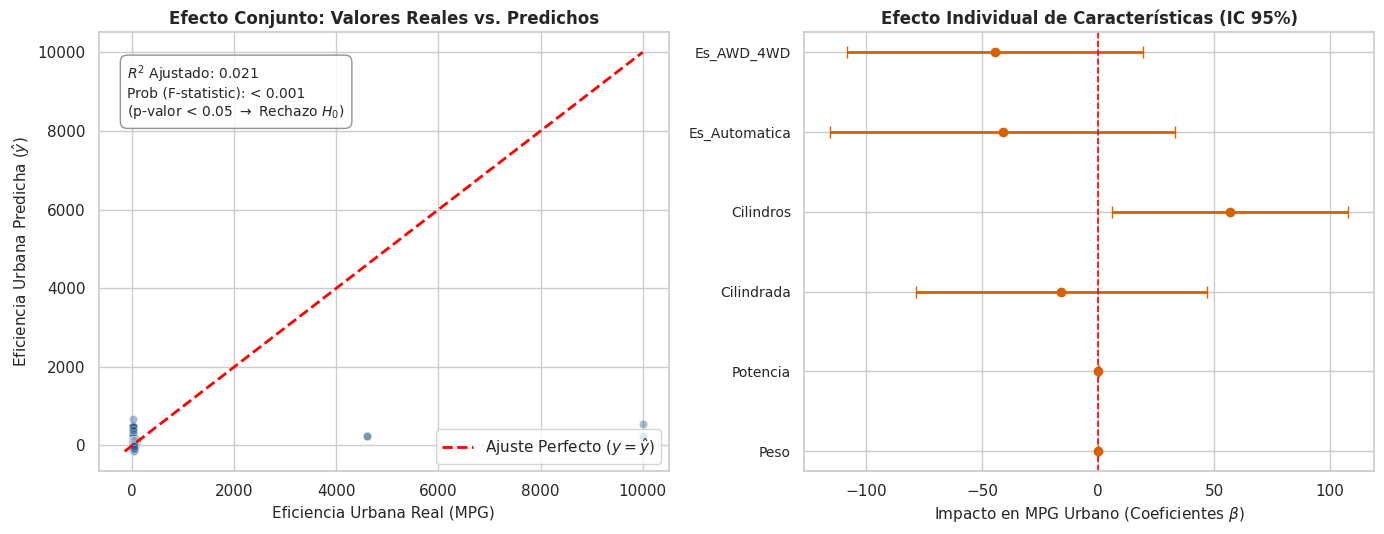

In [281]:

## CHeuqear que hacer con estos gr'aficos adicioanales

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual estándar Colab
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ==============================================================================
# 1. GRÁFICO DE VALORES OBSERVADOS VS. PREDICHOS (EVIDENCIA DE AJUSTE GLOBAL)
# ==============================================================================
y_real = dataset['h6_df'][dataset['h6_var_dep']]
y_pred = modelo_h6.fittedvalues

# Diagrama de dispersión entre valor real y predicho
sns.scatterplot(x=y_real, y=y_pred, alpha=0.4, color='#2b5c8f', ax=axes[0])

# Línea de 45° (Ajuste Perfecto)
lims = [min(y_real.min(), y_pred.min()), max(y_real.max(), y_pred.max())]
axes[0].plot(lims, lims, color='red', linestyle='--', linewidth=2, label=r'Ajuste Perfecto ($y = \hat{y}$)')

# Cuadro informativo con métricas clave para el rechazo de H0
texto_stats = (
    f"$R^2$ Ajustado: {modelo_h6.rsquared_adj:.3f}\n"
    f"Prob (F-statistic): < 0.001\n"
    f"(p-valor < 0.05 $\\rightarrow$ Rechazo $H_0$)"
)
axes[0].text(
    0.05, 0.93, texto_stats, transform=axes[0].transAxes, fontsize=10,
    verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray')
)

axes[0].set_title('Efecto Conjunto: Valores Reales vs. Predichos', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Eficiencia Urbana Real (MPG)', fontsize=11)
axes[0].set_ylabel(r'Eficiencia Urbana Predicha ($\hat{y}$)', fontsize=11)
axes[0].legend(loc='lower right')

# ==============================================================================
# 2. GRÁFICO DE COEFICIENTES E INTERVALOS DE CONFIANZA DEL 95%
# ==============================================================================
# Extraemos coeficientes e intervalos (excluyendo la constante)
conf_int = modelo_h6.conf_int().drop('Intercept')
coefs = modelo_h6.params.drop('Intercept')

y_pos = np.arange(len(coefs))
axes[1].errorbar(
    coefs, y_pos, 
    xerr=[coefs - conf_int[0], conf_int[1] - coefs], 
    fmt='o', color='#d95f02', ecolor='#d95f02', elinewidth=2, capsize=4
)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.2)

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(coefs.index, fontsize=10)
axes[1].set_title('Efecto Individual de Características (IC 95%)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Impacto en MPG Urbano (Coeficientes $\\beta$)', fontsize=11)

plt.tight_layout()
plt.show()